# **Analysis**

## 1. Inspect the derm7pt dataset

In [1]:
import os
import pandas as pd
from derm7pt.dataset import Derm7PtDatasetGroupInfrequent

dir_release = 'release_v0'
derm_data = Derm7PtDatasetGroupInfrequent(
    dir_images=os.path.join(dir_release, 'images'),
    metadata_df=pd.read_csv(os.path.join(dir_release, 'meta/meta.csv')),
    train_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/train_indexes.csv'))['indexes']),
    valid_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/valid_indexes.csv'))['indexes']),
    test_indexes=list(pd.read_csv(os.path.join(dir_release, 'meta/test_indexes.csv'))['indexes']))

print(derm_data.df.shape)
print(derm_data.df.columns.tolist())
derm_data.df.head()

(1011, 27)
['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes', 'diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric', 'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric', 'dots_and_globules_numeric', 'regression_structures_numeric']


,case_num,diagnosis,seven_point_score,pigment_network,streaks,pigmentation,regression_structures,dots_and_globules,blue_whitish_veil,vascular_structures,...,case_id,notes,diagnosis_numeric,pigment_network_numeric,blue_whitish_veil_numeric,vascular_structures_numeric,pigmentation_numeric,streaks_numeric,dots_and_globules_numeric,regression_structures_numeric
0,1,basal cell carcinoma,0,absent,absent,absent,absent,absent,absent,arborizing,...,NaN,NaN,0,0,0,1,0,0,0,0
1,2,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,absent,...,NaN,NaN,0,0,0,0,0,0,2,0
2,3,basal cell carcinoma,1,absent,absent,absent,absent,irregular,absent,arborizing,...,NaN,NaN,0,0,0,1,0,0,2,0
3,4,basal cell carcinoma,4,absent,absent,absent,blue areas,irregular,present,within regression,...,NaN,NaN,0,0,1,1,0,0,2,1
4,5,basal cell carcinoma,1,absent,absent,diffuse irregular,absent,absent,absent,absent,...,NaN,NaN,0,0,0,0,2,0,0,0


- Each row is lesion abnormal spot or patch on the skin. This could be mole, birthmark etc. Lesions says nothing about the condition yet but the term simply points points out an observed abnormality in the skin

- **Diagnosis** contains the diagnosis in str form

- **Diagnosis_numeric** contains the the diagnosis as numeric label. BCC(0), NEW(1), MEL(2), MISC(3), SK(4)

- **seven_point_score** contains the overall score for the lesion based on the 7 criteria. The score can kinda be abstracted from the values in the other columns like " pigementation" etc. " blue dots". 3 or more means suspiscious for melanoma calls for biopsy.

- **Criterion_numeric** the numeric columns converts the "typical/absent/atypical" into numeric values 0,1,2. This is what CBM model needs to be trained on. 



In [2]:
print(derm_data.df.shape)
print(derm_data.df.columns.tolist())

derm_data.dataset_stats()   # train / valid / test sizes

# Class balance of diagnosis and the 7 concepts in the training set
for col in ['diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric',
            'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric',
            'dots_and_globules_numeric', 'regression_structures_numeric']:
    print(col, derm_data.train[col].value_counts().sort_index().to_dict())

(1011, 27)
['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes', 'diagnosis_numeric', 'pigment_network_numeric', 'blue_whitish_veil_numeric', 'vascular_structures_numeric', 'pigmentation_numeric', 'streaks_numeric', 'dots_and_globules_numeric', 'regression_structures_numeric']
Number of cases: 1011
Number of cases to train: 413
Number of cases to validate: 203
Number of cases to test: 395
diagnosis_numeric {0: 19, 1: 256, 2: 90, 3: 32, 4: 16}
pigment_network_numeric {0: 160, 1: 160, 2: 93}
blue_whitish_veil_numeric {0: 339, 1: 74}
vascular_structures_numeric {0: 347, 1: 43, 2: 23}
pigmentation_numeric {0: 253, 1: 44, 2: 116}
streaks_numeric {0: 273, 1: 39, 2: 101}
dots_and_globules_numeric {0: 84, 1: 156, 2: 173}
regression_structures_numeric 

In [3]:
import numpy as np

# 7-point checklist criteria: concept = 1 if the *suspicious* variant is present (score > 0 in derm7pt)
CONCEPTS = {
    'Atypical pigment network':     ('pigment_network_numeric',       [2], 2),
    'Blue-whitish veil':            ('blue_whitish_veil_numeric',     [1], 2),
    'Atypical vascular structures': ('vascular_structures_numeric',   [2], 2),
    'Irregular pigmentation':       ('pigmentation_numeric',          [2], 1),
    'Irregular streaks':            ('streaks_numeric',               [2], 1),
    'Irregular dots/globules':      ('dots_and_globules_numeric',     [2], 1),
    'Regression structures':        ('regression_structures_numeric', [1], 1),
}
CONCEPT_NAMES = list(CONCEPTS)
CLASS_NAMES = ['BCC', 'NEV', 'MEL', 'MISC', 'SK']

df = derm_data.df
C = np.stack([df[col].isin(vals).values for col, vals, _ in CONCEPTS.values()], axis=1).astype(np.float32)
Y = df['diagnosis_numeric'].values.astype(np.int64)

meta = os.path.join(dir_release, 'meta')
split_idx = {s: pd.read_csv(os.path.join(meta, f'{s}_indexes.csv'))['indexes'].values
             for s in ['train', 'valid', 'test']}

# Sanity check: weighted sum of our concepts should reproduce the official 7-point score
weights = np.array([w for _, _, w in CONCEPTS.values()])
match = (C @ weights == df['seven_point_score'].values).mean()
print(f'7-pt score reproduced for {match:.1%} of cases')

print(pd.DataFrame(C[split_idx['train']], columns=CONCEPT_NAMES).mean().round(2).to_string())

7-pt score reproduced for 100.0% of cases
Atypical pigment network        0.23
Blue-whitish veil               0.18
Atypical vascular structures    0.06
Irregular pigmentation          0.28
Irregular streaks               0.24
Irregular dots/globules         0.42
Regression structures           0.23


In [4]:
import torch, torchvision
from torchvision import transforms
from PIL import Image
from tqdm import tqdm

IMG_TYPE = 'derm'                      # 'derm' = dermoscopic, 'clinic' = clinical photo
FEAT_FILE = f'features_{IMG_TYPE}_resnet50.npy'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

backbone = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
backbone.fc = torch.nn.Identity()      # output the 2048-d feature vector instead of ImageNet classes
backbone.eval().to(device)

preprocess = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load(i):
    img = derm_data.derm_image(i) if IMG_TYPE == 'derm' else derm_data.clinic_image(i)  # crops black border
    return preprocess(Image.fromarray(img))

if os.path.exists(FEAT_FILE):
    X = np.load(FEAT_FILE)
else:
    feats, n, bs = [], len(df), 32
    with torch.no_grad():
        for s in tqdm(range(0, n, bs)):
            batch = torch.stack([load(i) for i in range(s, min(s + bs, n))]).to(device)
            feats.append(backbone(batch).cpu().numpy())
    X = np.concatenate(feats)
    np.save(FEAT_FILE, X)

print(X.shape)   # expect (1011, 2048)

(1011, 2048)


## 2. Build concept bottleneck model

## 3. Setup model so it can be trained with the 3 training regimes

## 4. Assess model performance

In [7]:
import cbm, importlib; importlib.reload(cbm)

D = cbm.make_data(X, C, Y, split_idx, n_classes=len(CLASS_NAMES))

models = {}
models['independent'] = cbm.train_independent(D)
models['sequential']  = cbm.train_sequential(D, concept_model=models['independent'])  # same g, fair comparison

# Joint: choose lambda on the VALIDATION set
joint_runs = {lam: cbm.train_joint(D, lam=lam) for lam in [0.1, 1.0, 10.0]}
for lam, m in joint_runs.items():
    print(f'joint lambda={lam}: val bal_acc = {cbm.evaluate(m, D, "va")["bal_acc"]:.3f}')
best_lam = max(joint_runs, key=lambda l: cbm.evaluate(joint_runs[l], D, 'va')['bal_acc'])
models[f'joint (λ={best_lam})'] = joint_runs[best_lam]

models['black-box (no concepts)'] = cbm.train_blackbox(D)

joint lambda=0.1: val bal_acc = 0.329
joint lambda=1.0: val bal_acc = 0.280
joint lambda=10.0: val bal_acc = 0.254


,acc,bal_acc,macro_f1,concept_acc,concept_auc
independent,0.377,0.238,0.185,0.618,0.665
sequential,0.233,0.259,0.145,0.618,0.665
joint (λ=0.1),0.451,0.427,0.365,0.540,0.553
black-box (no concepts),0.294,0.374,0.267,NaN,NaN


,independent,sequential,joint (λ=0.1)
Atypical pigment network,0.666,0.666,0.570
Blue-whitish veil,0.694,0.694,0.701
Atypical vascular structures,0.628,0.628,0.488
Irregular pigmentation,0.657,0.657,0.361
Irregular streaks,0.678,0.678,0.666
Irregular dots/globules,0.656,0.656,0.643
Regression structures,0.677,0.677,0.444


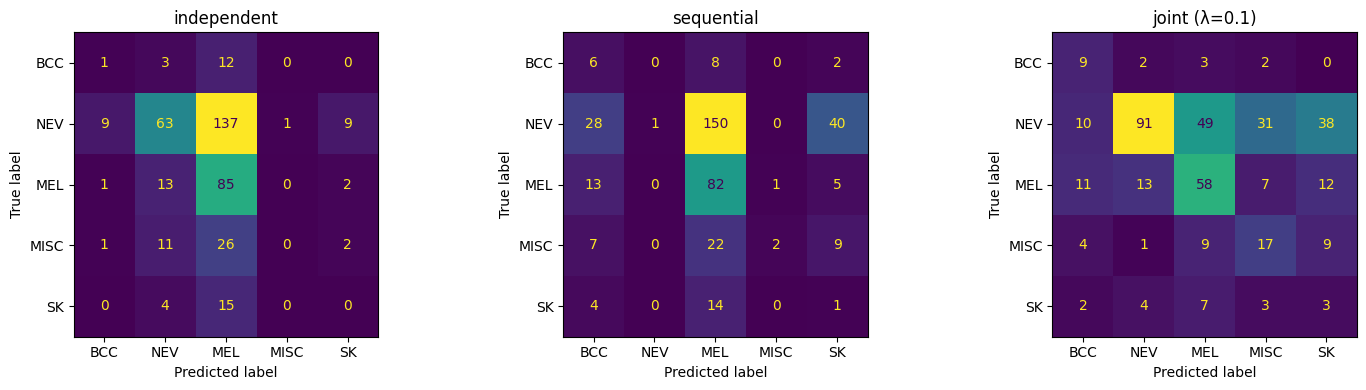

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Overall test performance per model
results = pd.DataFrame({name: cbm.evaluate(m, D, 'te') for name, m in models.items()}).T
display(results.round(3))

# 2) Per-concept test AUC per regime
concept_models = {k: v for k, v in models.items() if not k.startswith('black')}
display(pd.DataFrame({k: cbm.per_concept_auc(m, D, CONCEPT_NAMES) for k, m in concept_models.items()}).round(3))

# 3) Confusion matrices
fig, axes = plt.subplots(1, len(concept_models), figsize=(5 * len(concept_models), 4))
for ax, (name, m) in zip(axes, concept_models.items()):
    with torch.no_grad():
        y_pred = m(D['Xte'])[2].argmax(1).numpy()
    ConfusionMatrixDisplay.from_predictions(D['Yte'].numpy(), y_pred, display_labels=CLASS_NAMES,
                                            ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

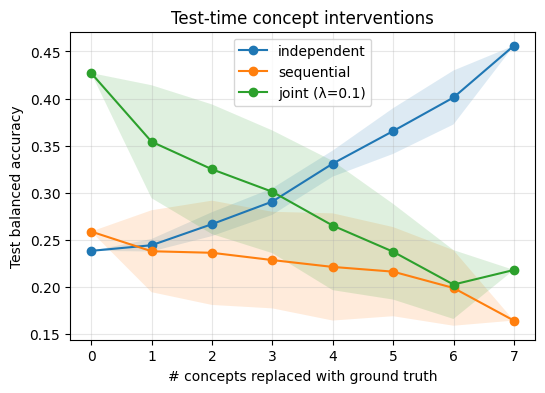

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
for name, m in concept_models.items():
    mean, std = cbm.intervention_curve(m, D, n_orders=20)
    ks = np.arange(len(mean))
    plt.plot(ks, mean, marker='o', label=name)
    plt.fill_between(ks, mean - std, mean + std, alpha=0.15)
plt.xlabel('# concepts replaced with ground truth'); plt.ylabel('Test balanced accuracy')
plt.title('Test-time concept interventions'); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [10]:
Yte = D['Yte'].numpy()
print('Test class counts      :', dict(zip(CLASS_NAMES, np.bincount(Yte, minlength=5))))
print('Always-NEV baseline acc:', round((Yte == 1).mean(), 3))

# What each model predicts (how many test cases per class)
for name, m in models.items():
    with torch.no_grad():
        out = m(D['Xte'])
        pred = (out if isinstance(m, cbm.BlackBox) else out[2]).argmax(1).numpy()
    print(f'{name:28s} predicts:', dict(zip(CLASS_NAMES, np.bincount(pred, minlength=5))))

# Oracle: label head fed the TRUE test concepts (upper bound of what the concepts can do)
print()
for name, m in concept_models.items():
    with torch.no_grad():
        pred = m.f(D['Cte']).argmax(1).numpy()
    print(f'{name:28s} with TRUE concepts:', {k: round(v, 3) for k, v in cbm.label_metrics(Yte, pred).items()})

Test class counts      : {'BCC': np.int64(16), 'NEV': np.int64(219), 'MEL': np.int64(101), 'MISC': np.int64(40), 'SK': np.int64(19)}
Always-NEV baseline acc: 0.554
independent                  predicts: {'BCC': np.int64(12), 'NEV': np.int64(94), 'MEL': np.int64(275), 'MISC': np.int64(1), 'SK': np.int64(13)}
sequential                   predicts: {'BCC': np.int64(58), 'NEV': np.int64(1), 'MEL': np.int64(276), 'MISC': np.int64(3), 'SK': np.int64(57)}
joint (λ=0.1)                predicts: {'BCC': np.int64(36), 'NEV': np.int64(111), 'MEL': np.int64(126), 'MISC': np.int64(60), 'SK': np.int64(62)}
black-box (no concepts)      predicts: {'BCC': np.int64(53), 'NEV': np.int64(72), 'MEL': np.int64(66), 'MISC': np.int64(59), 'SK': np.int64(145)}

independent                  with TRUE concepts: {'acc': 0.372, 'bal_acc': 0.456, 'macro_f1': 0.331}
sequential                   with TRUE concepts: {'acc': 0.21, 'bal_acc': 0.164, 'macro_f1': 0.074}
joint (λ=0.1)                with TRUE concepts: {'a

## 5. Exploratory study of the explanations given by the concepts

## 6. Suggest 3 potential use cases of model explanations

- Assuming this is conceptual and general, so our findings or models are not needed to adress this


**Example 1**
- Use case: User is a dermatologitst. They can use it for decision support where the model show hcich checklist criteria it sees, adn the doctor confirms or correct them befor deciding

- Success criterion:
Doctors with the CBM reach higher balanced accuracy than doctors alone or doctors with a black box AI. 
However there are studies that show doctor abilities degrading as a result of use of AI in medical diagnosis.


**Example 2**:
- Use case: User is a medical student. Use case is learning the 7 - point checklist with concept level feedback on each of the 7 criteria. Without the CBM the student looks at the image and gives a diagnosis if wrong labelled wrong they might miss a leanring opportunity. With the CBM tool they can see the presence of the 7 criterias.

- Success criterion:
Students trained with the tool score higher on a checklist test, and agree more with expert annotations than a control group.

**Example 3**:
- Use case:

- Success criterion:


# **Poster**

Introduction:
Data:
Method:
Validation pipeline:
Results:
Discussion:

MUST HAVES:
- Joint regime with $\lambda=1$ 
- "Exploratory study of the explanations" show 2-3 test images with their predicted vs true concepts and how an intervention changes the diangosis
- the 3 use cases with measurebale success. This is the hardest one, let someone else do it.

## *Introduction*

# **Understanding**

## *What is a concept bottleneck model?*

- Say we want a dianostic tools using images. Instead of giving the diagnosis directly from the image we have an intermediate layer where first predict the symptoms observed and then we predict the diagnosis

- We introduce a concept predictor g, which is what predicts on the source material, then we introduce the label predictor f which make the final predictions from the concepts of g

- This builts in intrisic interpretability the explanation is built into the mode not added afterwards unlike gradcam

- Concept g still needs to be trained against dermatologist labels ( supervised labelling)

- g is still a blackbox CBM narrows the black box but doesnt remove it

## *What is the 7 point checklist?*

## *What are the 3 training regimes ( independent, sequential, joint)?*

- Independet: g learns to predict the concepts from the images, f learns the true concepts and predicts the diagnosis. f has never seen g or adapted to g mistakes so it can exploit or fail on the gnals in it 

- But this would be the worst model ? 

- Sequential we train g and then train f and feed g output into f 

- joint we train g and f together they affect the loss function simultaneously and in backpropagatin both their weight s are updated. the diagnosis loss flows back to g so g is pushed into output whatever helps the diagnosis. this is the leakage. 

- small lambda close to black box, large lamda enforces the concepts

- leakage can aso happen in sequential models since output of g may carry information that f leanrs to exploit. 

- Independent is the safest since f only interacats with g in test and wieght are never updated based on the outptus of g 



## *What is transfer learning?*

- Refers to the example of using a CNN model trained on a different image dataset and apply in a nother. This can be done because the task a generic or similar even though the problems might different

## *What is frozen?*

- Can be thought of as an alternative to fine tuning

- Frozen just refers to any modle where we dont update the weight anymore

- Fine tuning and training is actually the same thing. We can be training from scratch starting with random wieghts or we can have some pretrained models and fine tune their weights a bit more meaning wer just train them through mor epochs

## *How can you prove faithfullness?*

- It can only be tested

- We use interventions. I fthe model uses the concepts chaning them or correcting them should help. 

- If a mode does better with its own predicted concepts than with true ones its using something other than the concepts.

- Do the concepts mathc the dermatologist labels (AUC)

- Round predictions of concepts to 0/1 before f. If performance collapses the model relied on hidden information in decimals 

- check the weightst does the weight for the concepts push towards the conditions or as they should according to medicine 

- This is the validation pipeline for eplanations